# Métricas e treinamento · Random Forest

GridSearchCV reproduzível, baseline e diagnósticos de **treino e validação**.
**TEST não é avaliado neste notebook.** Os gráficos leem artefatos persistidos;
abrir ou executar o notebook com a configuração padrão não repete a busca.

## 1. Protocolo e origem das métricas

- Alvo `Machine failure`, positivo `1`. Entradas: cinco sensores e `Type`.
- Mesma reserva da EDA: 8.000 registros de desenvolvimento e 2.000 em TEST reservado.
- Dentro dos 8.000: prefixo **FIT de 6.400** para GridSearchCV, seguido de **1.600 em VALIDAÇÃO**.
- Três folds com prefixos crescentes dentro de FIT, sem shuffle ou gap. UDI é ordem,
  não data real; não se demonstra independência temporal nem entre máquinas.
- **Critério:** maior média de AP na CV; empate exato usa primeiro candidato da grade.
  AP é Average Precision, não integração trapezoidal da PR. O vencedor é o melhor
  da grade pesquisada, sem garantia de ótimo global.
- **Refit:** melhores parâmetros reajustados apenas nas 6.400 observações FIT.
  A validação de 1.600 não participa do ajuste nem do GridSearchCV.
- **Decisão:** `score >= 0.5`, referência fixa e não limiar operacional ótimo.
- Imputação e one-hot dentro do pipeline/folds; árvores sem scaling. Sem SMOTE,
  undersampling, seleção automática de features, calibração ajustada ou early stopping.
- TRAIN completo já participou da EDA: a validação é interna ao desenvolvimento,
  não uma confirmação independente. Os scores do vencedor na CV têm otimismo de seleção.

In [1]:
from pathlib import Path
import sys
import json
from IPython.display import display, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'configs/training.json').is_file() and (p / 'pyproject.toml').is_file())
sys.path.insert(0, str(ROOT / 'src'))
from predictive_maintenance.training import run_experiment, latest_run
from predictive_maintenance.reporting import ModelReport
from predictive_maintenance.presentation import readable_table, readable_parameters, translate_text

def translated_markdown(text):
    return Markdown(translate_text(text))

from predictive_maintenance.data import sha256

MODEL_NAME = 'random_forest'
RUN_TRAINING = False  # True executa uma nova busca e preserva as anteriores.
RUN_ID = None  # Informe um ID salvo para revisar exatamente aquela execução.
if RUN_TRAINING:
    run = run_experiment(ROOT, MODEL_NAME)
elif RUN_ID:
    run = ROOT / 'reports/experiments' / RUN_ID
else:
    run = latest_run(ROOT, MODEL_NAME)
report = ModelReport(ROOT, run)
manifest = report.manifest
if manifest['model'] != MODEL_NAME:
    raise ValueError('Execução pertence a outro modelo.')
print('Execução:', manifest['run_id'])
print('Dataset SHA256:', manifest['dataset_sha256'])
print('CSV atual corresponde:', sha256(ROOT / manifest['data_config']['source']) == manifest['dataset_sha256'])
print('TEST avaliado:', manifest['test_evaluated'])
display(manifest['versions'])

Execução: train_random_forest_20261031T234425Z_5a1caa57
Dataset SHA256: dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1dd5c4340ac56bc8a8e
CSV atual corresponde: True
TEST avaliado: False


{'scikit-learn': '1.9.1',
 'xgboost': '3.4.1',
 'pandas': '2.3.3',
 'numpy': '2.5.4',
 'scipy': '1.18.1',
 'joblib': '1.6.0',
 'imbalanced-learn': '0.14.2'}

## 2. Grade, custo e melhores parâmetros

Cada modelo pesquisa 32 candidatos × 3 folds = 96 ajustes de busca, mais um refit.
Há ainda 4 ajustes do baseline e 3 diagnósticos de tamanho com parâmetros congelados.
A busca usa 2 workers e cada estimador usa 1 thread para limitar concorrência.

**Nomenclatura sklearn:** `mean_test_*` e `split*_test_*` nas tabelas da busca
significam validação dos folds dentro de FIT, nunca o conjunto TEST reservado.

A grade investiga quantidade de árvores, profundidade, suporte mínimo de folhas,
número de features por divisão e `class_weight`. `balanced` calcula os pesos
com os rótulos do treino de cada fit. Critério Gini, bootstrap e
`min_samples_split=2` são **fixos**, não otimizados nesta rodada.

Parâmetro,Descrição,Valor
model__n_estimators,Número de árvores,"[150, 300]"
model__max_depth,Profundidade máxima,"[None, 10]"
model__min_samples_leaf,Observações mínimas por folha,"[1, 4]"
model__max_features,Variáveis por divisão,"['sqrt', 1.0]"
model__class_weight,Peso das classes,"[None, 'balanced']"


**Parâmetros fixos:**

Parâmetro,Descrição,Valor
criterion,Critério de divisão,gini
bootstrap,Amostragem com reposição,True
min_samples_split,Observações mínimas para dividir,2
n_jobs,Threads do estimador,1


**Melhores parâmetros na grade:**

Parâmetro,Descrição,Valor
model__class_weight,Peso das classes,None
model__max_depth,Profundidade máxima,10
model__max_features,Variáveis por divisão,sqrt
model__min_samples_leaf,Observações mínimas por folha,1
model__n_estimators,Número de árvores,300


AP média de seleção: 0.5076
Tempo da busca: 123.5 s


,AP (score) — posição — validação CV,AP (score) — média — validação CV,AP (score) — desvio — validação CV,AP (score) — média — treino CV,AUPRC trapezoidal (score) — média — validação CV,F1 (%) — média — validação CV,Recall (%) — média — validação CV,Precision (%) — média — validação CV,Tempo médio de ajuste (s),Parâmetros
9,1,"0,5076","0,0992","0,9991","0,5037","40,85%","41,93%","66,82%","2,0468","{""model__class_weight"": null, ""model__max_depth"": 10, ""model__max_features"": ""sqrt"", ""model__min_samples_leaf"": 1, ""model__n_estimators"": 300}"
8,2,"0,5073","0,1015","0,9990","0,5041","39,25%","40,08%","66,23%","1,0314","{""model__class_weight"": null, ""model__max_depth"": 10, ""model__max_features"": ""sqrt"", ""model__min_samples_leaf"": 1, ""model__n_estimators"": 150}"
13,3,"0,4965","0,1378","0,9989","0,4960","45,23%","47,82%","46,65%","4,5450","{""model__class_weight"": null, ""model__max_depth"": 10, ""model__max_features"": 1.0, ""model__min_samples_leaf"": 1, ""model__n_estimators"": 300}"
1,4,"0,4885","0,1181",1,"0,4841","41,77%","42,97%","67,11%","2,1599","{""model__class_weight"": null, ""model__max_depth"": null, ""model__max_features"": ""sqrt"", ""model__min_samples_leaf"": 1, ""model__n_estimators"": 300}"
14,5,"0,4876","0,1340","0,9578","0,4884","42,44%","45,40%","61,03%","2,1762","{""model__class_weight"": null, ""model__max_depth"": 10, ""model__max_features"": 1.0, ""model__min_samples_leaf"": 4, ""model__n_estimators"": 150}"
6,6,"0,4857","0,1353","0,9600","0,4875","42,09%","44,64%","60,81%","2,2178","{""model__class_weight"": null, ""model__max_depth"": null, ""model__max_features"": 1.0, ""model__min_samples_leaf"": 4, ""model__n_estimators"": 150}"
15,7,"0,4855","0,1304","0,9578","0,4857","40,60%","43,37%","59,37%","4,2842","{""model__class_weight"": null, ""model__max_depth"": 10, ""model__max_features"": 1.0, ""model__min_samples_leaf"": 4, ""model__n_estimators"": 300}"
7,8,"0,4838","0,1316","0,9603","0,4844","40,60%","43,37%","59,37%","4,4262","{""model__class_weight"": null, ""model__max_depth"": null, ""model__max_features"": 1.0, ""model__min_samples_leaf"": 4, ""model__n_estimators"": 300}"
3,9,"0,4815","0,1025","0,9568","0,4770","27,31%","27,20%","67,20%","2,1006","{""model__class_weight"": null, ""model__max_depth"": null, ""model__max_features"": ""sqrt"", ""model__min_samples_leaf"": 4, ""model__n_estimators"": 300}"
11,10,"0,4792","0,1011","0,9501","0,4750","27,69%","27,43%","67,33%","2,0344","{""model__class_weight"": null, ""model__max_depth"": 10, ""model__max_features"": ""sqrt"", ""model__min_samples_leaf"": 4, ""model__n_estimators"": 300}"


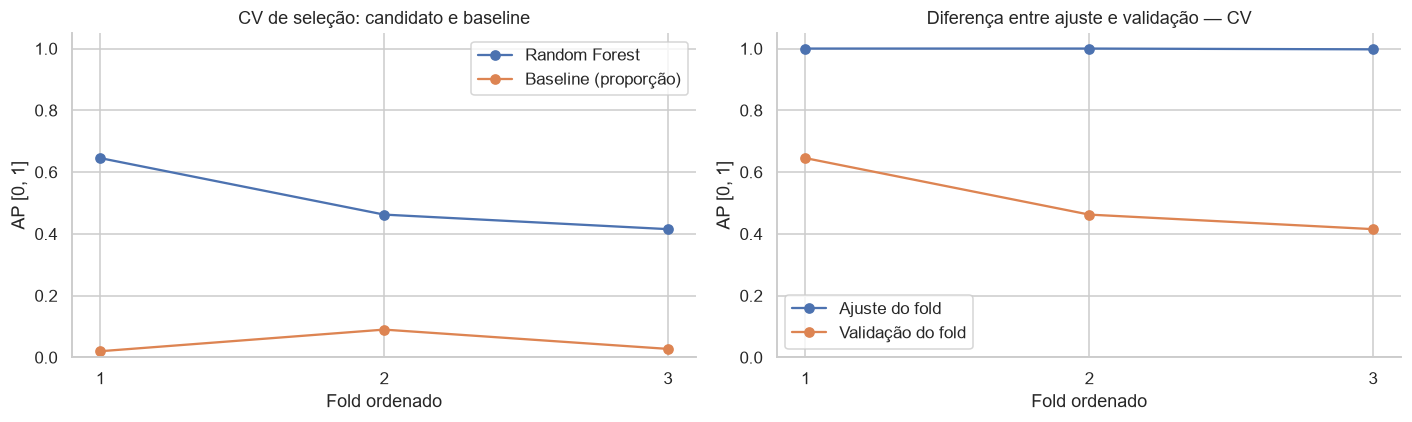

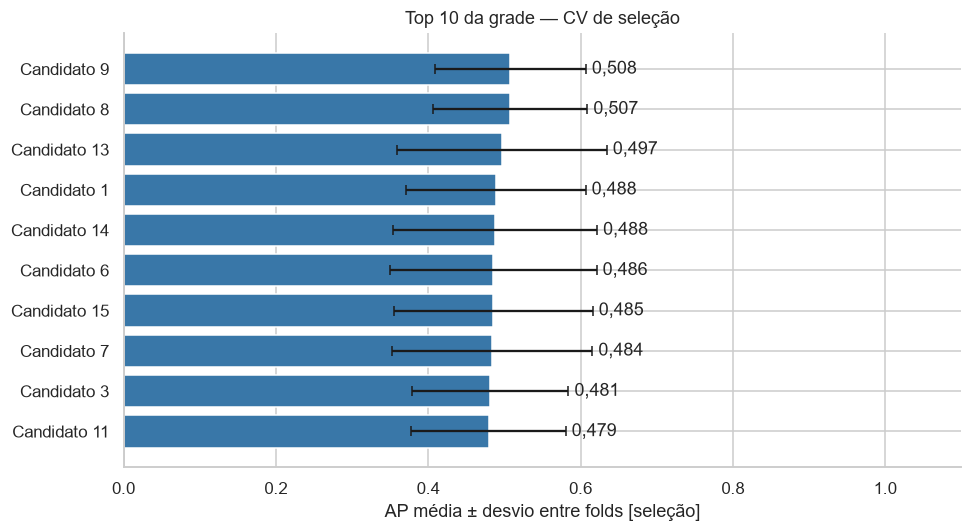

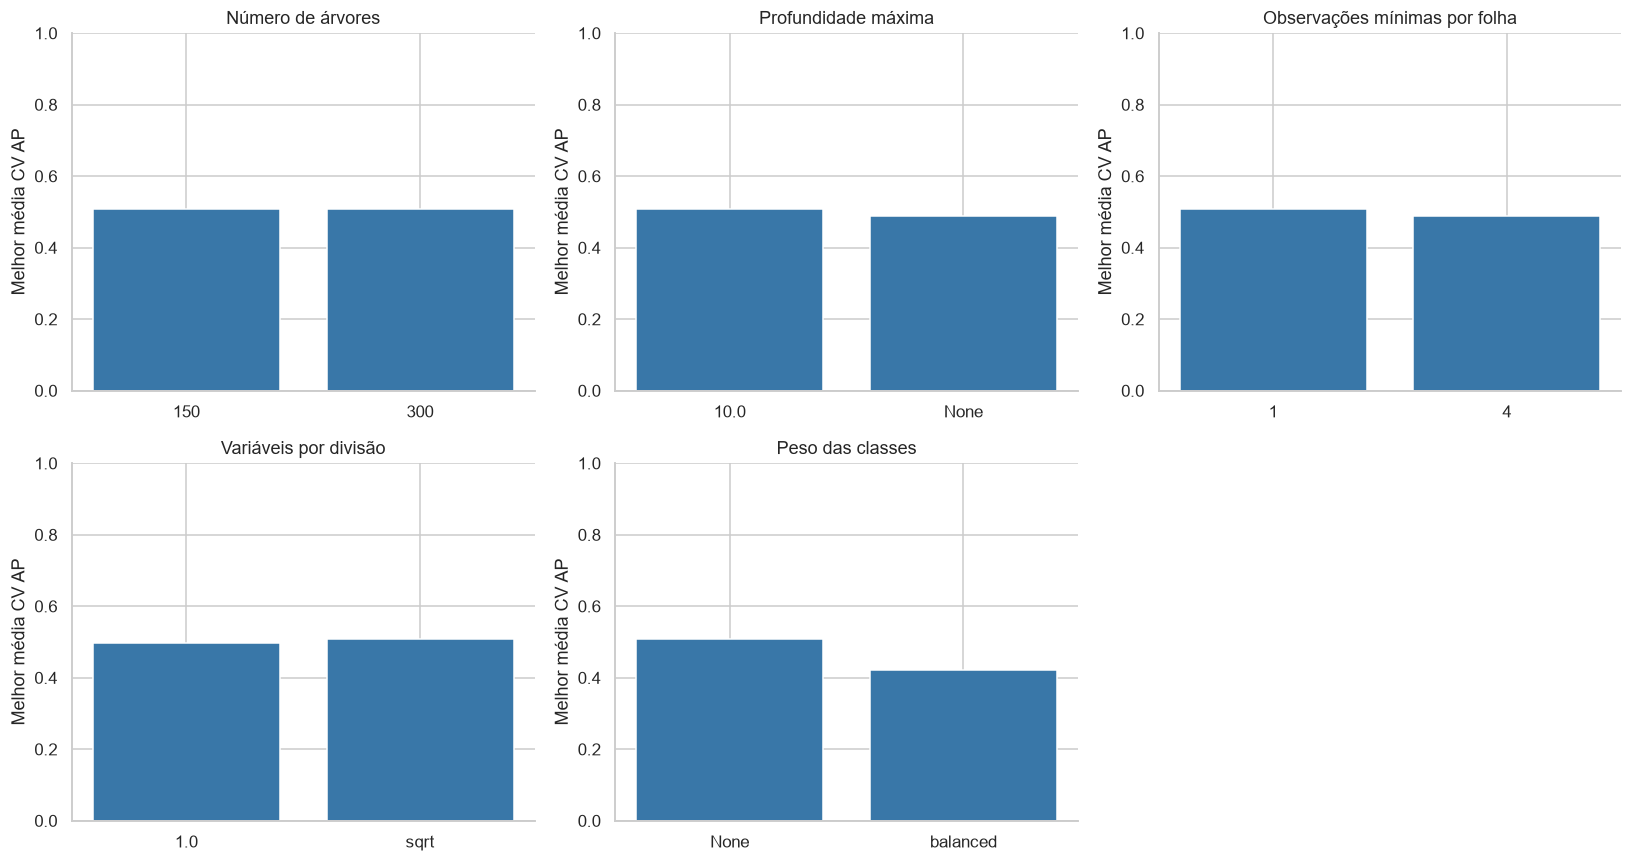

In [2]:
display(readable_parameters(manifest['training_config'][MODEL_NAME]['grid']))
display(translated_markdown('**Parâmetros fixos:**'))
display(readable_parameters(manifest['fixed_params']))
display(translated_markdown('**Melhores parâmetros na grade:**'))
display(readable_parameters(manifest['best_params']))
print(f"AP média de seleção: {manifest['best_cv_ap']:.4f}")
print(f"Tempo da busca: {manifest['search_seconds']:.1f} s")
grid = report.table('grid_results')
selection_metric = manifest.get('selection_metric', 'ap')
columns = [f'rank_test_{selection_metric}', f'mean_test_{selection_metric}', f'std_test_{selection_metric}', f'mean_train_{selection_metric}', 'mean_test_ap', 'mean_test_auprc',
           'mean_test_f1', 'mean_test_recall', 'mean_test_precision', 'mean_fit_time', 'params']
display(readable_table(grid.sort_values(f'rank_test_{selection_metric}')[list(dict.fromkeys(columns))].head(10)))
report.cv_figures()

**Leitura dos perfis:** cada barra mostra o melhor AP médio entre combinações
daquele valor, mantendo os demais parâmetros livres na grade. Não é efeito
isolado de hiperparâmetro. Os desvios do top 10 são dispersão entre folds,
não intervalos de confiança ou evidência de superioridade estatística.

## 3. Estatísticas por fold e baseline

`CV_SELECTION` refere-se ao candidato escolhido nas mesmas amostras usadas na
seleção, sem CV aninhada. Não são predições OOF nem resultado de teste.
O baseline Dummy usa a proporção observada no treino de cada fold.
Precision sem alertas é 0 no scorer da CV; nos diagnósticos de segmentos é indefinida (NaN).

In [3]:
folds = report.table('fold_metrics')
display(readable_table(folds))
display(readable_table(report.summary()))
selected_folds = folds.loc[folds.model.eq(MODEL_NAME)]
display(translated_markdown(f"**AP de seleção:** {selected_folds.validation_ap.mean():.3f} ± "
                f"{selected_folds.validation_ap.std(ddof=1):.3f} (desvio amostral entre folds). "
                'Deslocamentos entre blocos e baixo suporte positivo limitam a interpretação.'))

,Receita,Fold ordenado,Origem,Observações de treino,Observações de validação,Falhas no treino,Falhas na validação,Limiar de alerta,AP (score) — treino,AP (score) — validação,ROC-AUC (score) — treino,ROC-AUC (score) — validação,F1 (%) — treino,F1 (%) — validação,Recall (%) — treino,Recall (%) — validação,Precision (%) — treino,Precision (%) — validação,Acurácia balanceada (%) — treino,Acurácia balanceada (%) — validação,AUPRC trapezoidal (score) — treino,AUPRC trapezoidal (score) — validação
0,Random Forest,1,CV de seleção,1.600,1.600,45,32,"0,5000","1,0000","0,6453",1,"0,9458","100,00%","60,00%","100,00%","46,88%","100,00%","83,33%","100,00%","73,34%","1,0000","0,6426"
1,Baseline (proporção),1,CV do baseline,1.600,1.600,45,32,"0,5000","0,0281","0,0200","0,5000","0,5000","0,00%","0,00%","0,00%","0,00%","0,00%","0,00%","50,00%","50,00%","0,5141","0,5100"
2,Random Forest,2,CV de seleção,3.200,1.600,77,144,"0,5000",1,"0,4624",1,"0,8861","94,52%","26,19%","89,61%","15,28%","100,00%","91,67%","94,81%","57,57%",1,"0,4575"
3,Baseline (proporção),2,CV do baseline,3.200,1.600,77,144,"0,5000","0,0241","0,0900","0,5000","0,5000","0,00%","0,00%","0,00%","0,00%","0,00%","0,00%","50,00%","50,00%","0,5120","0,5450"
4,Random Forest,3,CV de seleção,4.800,1.600,221,44,"0,5000","0,9974","0,4153","0,9999","0,9179","95,01%","36,36%","90,50%","63,64%","100,00%","25,45%","95,25%","79,18%","0,9974","0,4111"
5,Baseline (proporção),3,CV do baseline,4.800,1.600,221,44,"0,5000","0,0460","0,0275","0,5000","0,5000","0,00%","0,00%","0,00%","0,00%","0,00%","0,00%","50,00%","50,00%","0,5230","0,5138"


**AP de seleção:** 0,508 ± 0,122 (desvio amostral entre folds). Deslocamentos entre blocos e baixo suporte positivo limitam a interpretação.

## 4. FIT reajustado versus VALIDAÇÃO

`FIT_RESUBSTITUTION` é desempenho sobre o próprio ajuste, sujeito a sobreajuste.
`VALIDATION_TRAIN_BLOCK` é o bloco posterior fora da busca. Mesmos dados e limiar
para o candidato e o baseline. Nas tabelas e barras, F1/Recall/Precision e taxas aparecem em %, com vírgula decimal; AP e ROC-AUC permanecem scores em 0–1. Desvios de percentuais são pontos percentuais (p.p.). Os artefatos numéricos não são alterados.
`Não definido` nas barras indica ausência de alertas; a altura 0 é apenas convenção visual.

,Receita,Origem,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),AUPRC trapezoidal (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,Random Forest,Treino (reavaliação no ajuste),6.400,265,"4,14%","0,5000",6.135,0,37,228,"92,49%","86,04%","100,00%","100,00%","99,40%","0,00%","13,96%","3,56%","99,42%","93,02%","0,9897","0,9896","0,9994","0,0069","0,0308","0,9248","0,9220"
1,Random Forest,Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.562,3,20,15,"56,60%","42,86%","83,33%","99,81%","98,74%","0,19%","57,14%","1,12%","98,56%","71,33%","0,7205","0,7180","0,9546","0,0111","0,0487","0,5917","0,5595"
2,Baseline (proporção),Treino (reavaliação no ajuste),6.400,265,"4,14%","0,5000",6.135,0,265,0,"0,00%","0,00%",Não definido,"100,00%","95,86%","0,00%","100,00%","0,00%","95,86%","50,00%","0,0414","0,5207","0,5000","0,0397","0,1724",0,0
3,Baseline (proporção),Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.565,0,35,0,"0,00%","0,00%",Não definido,"100,00%","97,81%","0,00%","100,00%","0,00%","97,81%","50,00%","0,0219","0,5109","0,5000","0,0218","0,1110",0,0


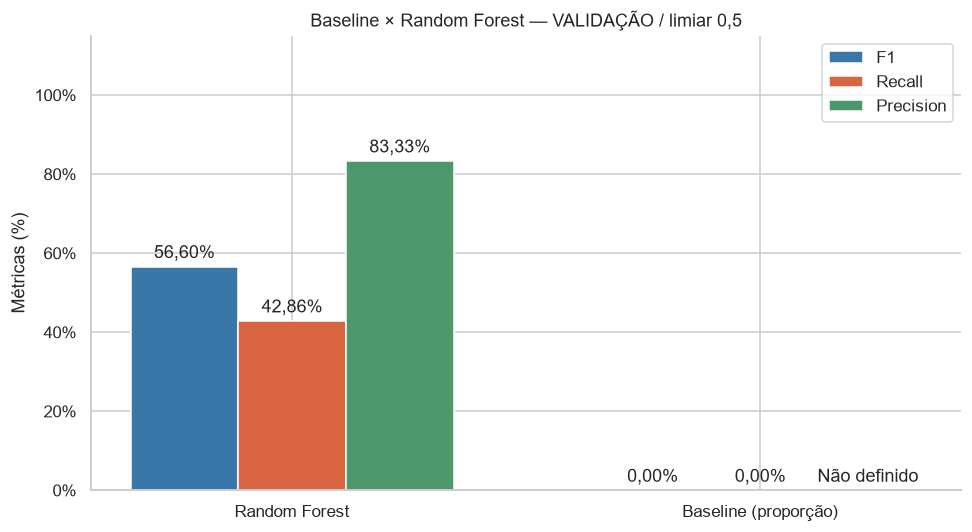

**Validação:** AUPRC=0,718; AUPRC=0,718; AUPRC=0,718; AP=0,720; F1=56,60%; Recall=42,86%; Precision=83,33%. Diferença de AP entre ajuste e validação = 0,269. São 35 falhas em 1600 observações. A diferença pode refletir sobreajuste e mudança entre blocos; não prova causalidade.

In [4]:
metrics = report.table('model_metrics')
display(readable_table(metrics))
report.comparison()
validation = metrics.loc[metrics.model.eq(MODEL_NAME) & metrics.origin.eq('VALIDATION_TRAIN_BLOCK')].iloc[0]
fit = metrics.loc[metrics.model.eq(MODEL_NAME) & metrics.origin.eq('FIT_RESUBSTITUTION')].iloc[0]
display(translated_markdown(f"**Validação:** AUPRC={validation.auprc:.3f}; AUPRC={validation.auprc:.3f}; AUPRC={validation.auprc:.3f}; AP={validation.ap:.3f}; F1={validation.f1:.2%}; "
    f"Recall={validation.recall:.2%}; Precision={validation.precision:.2%}. "
    f"Diferença de AP entre ajuste e validação = {fit.ap - validation.ap:.3f}. "
    f"São {int(validation.positives)} falhas em {int(validation.n)} observações. "
    'A diferença pode refletir sobreajuste e mudança entre blocos; não prova causalidade.'))

## 5. Matriz de confusão e relatório por classe

Eixo vertical real, horizontal previsto; classe positiva = falha. Matrizes em
contagens e normalizadas pela classe real. `zero_division=0` no relatório por classe.

,Classe / média,Precision (%),Recall (%),F1 (%),Observações da classe
0,Sem falha (0),"98,74%","99,81%","99,27%",1.565
1,Falha (1),"83,33%","42,86%","56,60%",35
2,Acurácia,"98,56%","98,56%","98,56%","0,9856"
3,Média macro,"91,03%","71,33%","77,94%",1.600
4,Média ponderada,"98,40%","98,56%","98,34%",1.600


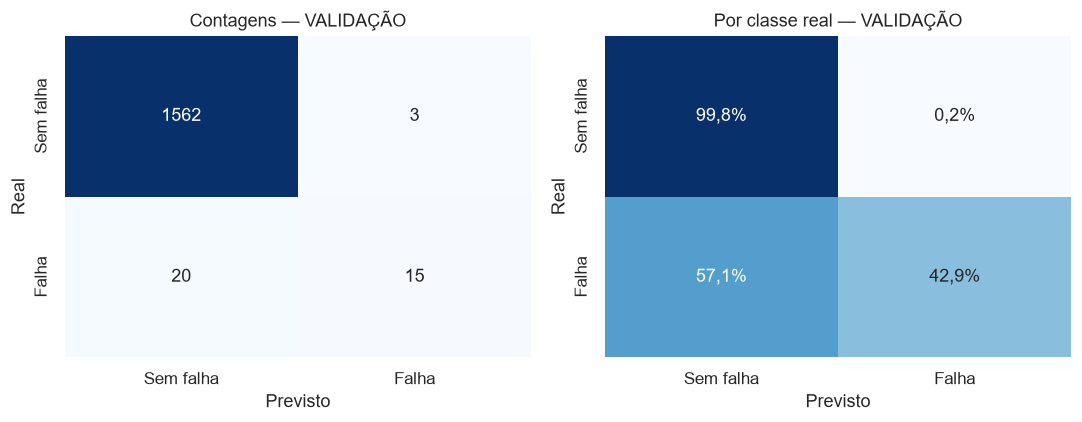

**Carga de revisão no bloco:** 18 alertas; 3 falsos positivos e 20 falhas perdidas. Custos e capacidade operacional ainda não foram informados.

In [5]:
display(readable_table(report.table('classification_report')))
report.confusion()
display(translated_markdown(f"**Carga de revisão no bloco:** {int(validation.tp + validation.fp)} alertas; "
                f"{int(validation.fp)} falsos positivos e {int(validation.fn)} falhas perdidas. "
                'Custos e capacidade operacional ainda não foram informados.'))

## 6. PR, ROC, confiabilidade e distribuição dos scores

AP e ROC usam scores positivos. A prevalência é a referência da PR. ROC complementa
a análise de classe rara. A curva de confiabilidade usa até 10 grupos por quantis;
não ajusta calibrador e não comprova calibração. Pesos de classe podem alterar os scores.

**Nota sobre AUPRC:** uma pontuação constante pode gerar poucos pontos na curva PR; a interpolação trapezoidal pode resultar em área alta mesmo com AP igual à prevalência. Por isso AP e AUPRC são mostradas separadamente, inclusive no baseline.

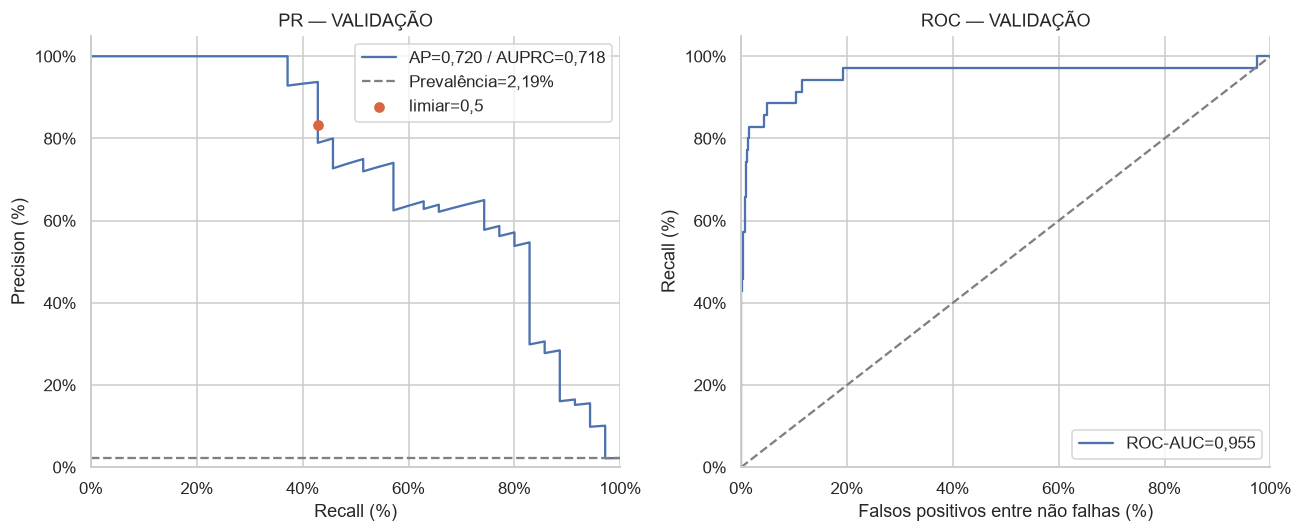

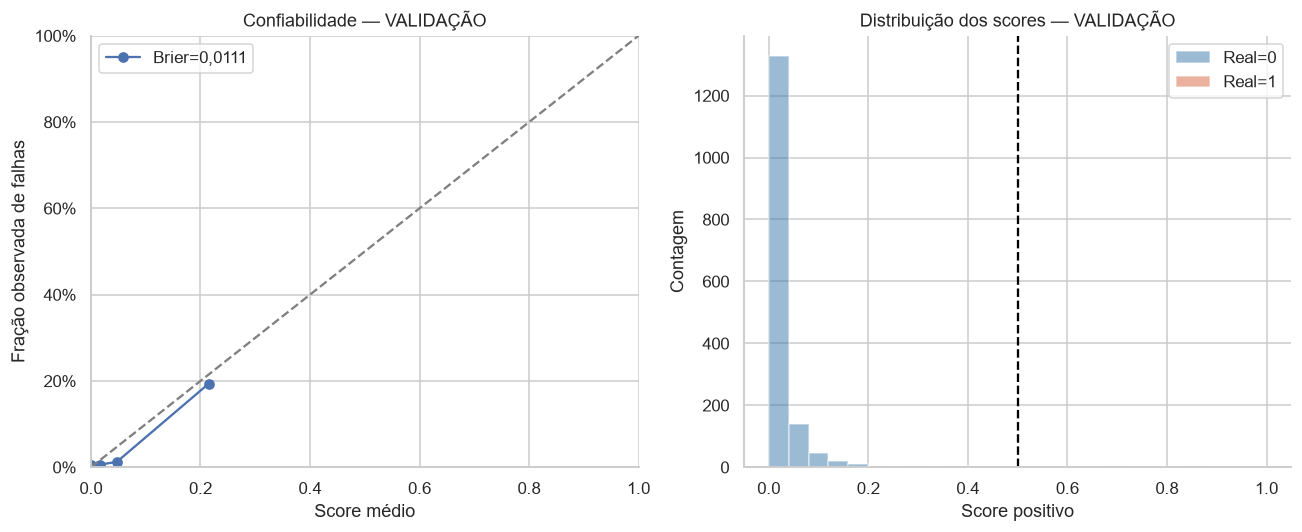

,Score médio,Taxa observada de falhas (%)
0,"0,0009","0,62%"
1,"0,0012","0,00%"
2,"0,0016","0,00%"
3,"0,0021","0,00%"
4,"0,0036","0,00%"
5,"0,0051","0,00%"
6,"0,0075","0,00%"
7,"0,0168","0,62%"
8,"0,0472","1,25%"
9,"0,2150","19,38%"


**Diagnóstico probabilístico:** Brier=0,0111; Log Loss=0,0487. Amostra com poucas falhas limita a estabilidade da curva de confiabilidade.

In [6]:
report.probability_figures()
display(readable_table(report.table('calibration')))
display(translated_markdown(f"**Diagnóstico probabilístico:** Brier={validation.brier:.4f}; "
                f"Log Loss={validation.log_loss:.4f}. "
                'Amostra com poucas falhas limita a estabilidade da curva de confiabilidade.'))

## 7. Sensibilidade ao threshold — sem tuning

O destaque mostra a referência 0,5. Varrer limiares na validação é **diagnóstico**,
sem mudar o pacote ou declarar um ótimo. Recall/Precision/F1 mudam; AP dos mesmos
scores não muda. Uma escolha operacional futura exige objetivo e validação própria.

,Origem,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),AUPRC trapezoidal (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,Validação (somente diagnóstico),1.600,35,"2,19%","0,0500",1.368,197,2,33,"24,91%","94,29%","14,35%","87,41%","99,85%","12,59%","5,71%","14,37%","87,56%","90,85%","0,7205","0,7180","0,9546","0,0111","0,0487","0,3406","0,2194"
1,Validação (somente diagnóstico),1.600,35,"2,19%","0,1000",1.499,66,6,29,"44,62%","82,86%","30,53%","95,78%","99,60%","4,22%","17,14%","5,94%","95,50%","89,32%","0,7205","0,7180","0,9546","0,0111","0,0487","0,4867","0,4279"
2,Validação (somente diagnóstico),1.600,35,"2,19%","0,2000",1.541,24,6,29,"65,91%","82,86%","54,72%","98,47%","99,61%","1,53%","17,14%","3,31%","98,12%","90,66%","0,7205","0,7180","0,9546","0,0111","0,0487","0,6647","0,6499"
3,Validação (somente diagnóstico),1.600,35,"2,19%","0,3000",1.551,14,11,24,"65,75%","68,57%","63,16%","99,11%","99,30%","0,89%","31,43%","2,38%","98,44%","83,84%","0,7205","0,7180","0,9546","0,0111","0,0487","0,6501","0,6496"
4,Validação (somente diagnóstico),1.600,35,"2,19%","0,4000",1.560,5,19,16,"57,14%","45,71%","76,19%","99,68%","98,80%","0,32%","54,29%","1,31%","98,50%","72,70%","0,7205","0,7180","0,9546","0,0111","0,0487","0,5834","0,5643"
5,Validação (somente diagnóstico),1.600,35,"2,19%","0,5000",1.562,3,20,15,"56,60%","42,86%","83,33%","99,81%","98,74%","0,19%","57,14%","1,12%","98,56%","71,33%","0,7205","0,7180","0,9546","0,0111","0,0487","0,5917","0,5595"
6,Validação (somente diagnóstico),1.600,35,"2,19%","0,6000",1.565,0,22,13,"54,17%","37,14%","100,00%","100,00%","98,61%","0,00%","62,86%","0,81%","98,62%","68,57%","0,7205","0,7180","0,9546","0,0111","0,0487","0,6052","0,5362"
7,Validação (somente diagnóstico),1.600,35,"2,19%","0,7000",1.565,0,25,10,"44,44%","28,57%","100,00%","100,00%","98,43%","0,00%","71,43%","0,62%","98,44%","64,29%","0,7205","0,7180","0,9546","0,0111","0,0487","0,5303","0,4390"
8,Validação (somente diagnóstico),1.600,35,"2,19%","0,8000",1.565,0,30,5,"25,00%","14,29%","100,00%","100,00%","98,12%","0,00%","85,71%","0,31%","98,12%","57,14%","0,7205","0,7180","0,9546","0,0111","0,0487","0,3744","0,2459"
9,Validação (somente diagnóstico),1.600,35,"2,19%","0,9000",1.565,0,35,0,"0,00%","0,00%",Não definido,"100,00%","97,81%","0,00%","100,00%","0,00%","97,81%","50,00%","0,7205","0,7180","0,9546","0,0111","0,0487",0,0


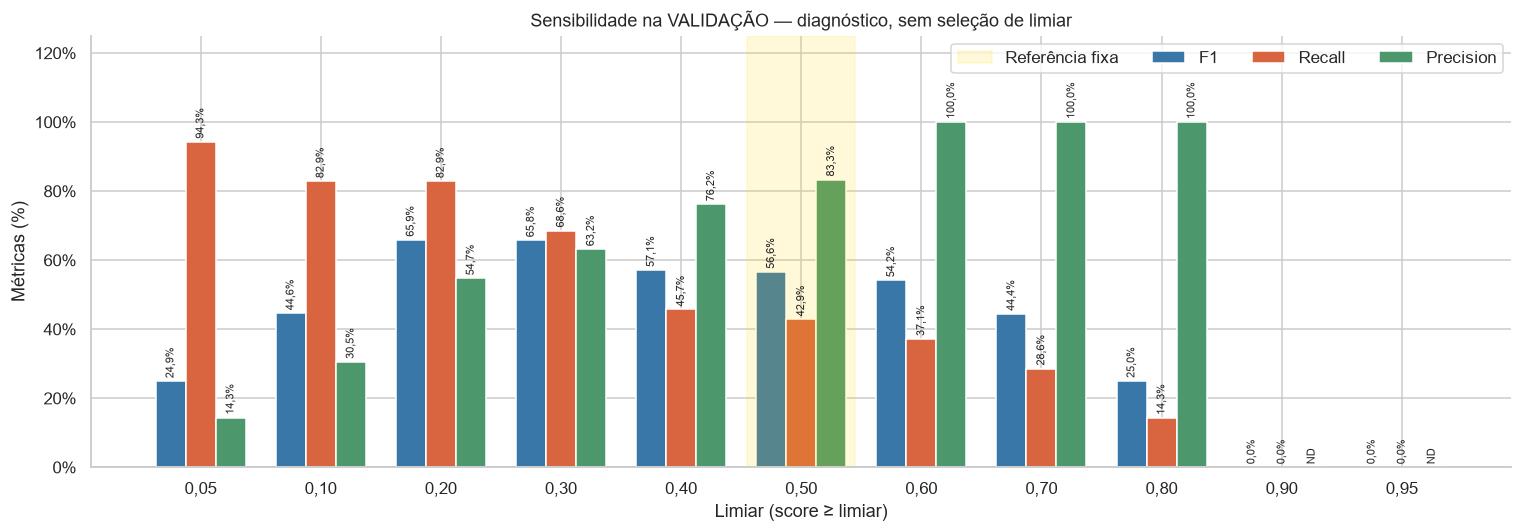

In [7]:
display(readable_table(report.table('threshold_diagnostics')))
report.threshold_figure()

## 8. Associação versus importância preditiva

Associação calculada em FIT: Spearman para sensores, Cramér V para Type (magnitude
com medidas distintas, não equivalentes). Importância por permutação no bloco de
validação, agregada por entrada original passando pelo pipeline completo.
A unidade é queda de AP; as barras de erro são desvio das permutações, não confiança.
Correlação entre sensores pode repartir importâncias. Nada foi removido com esse diagnóstico.

,Variável,Pearson com falha — treino,Spearman com falha — treino,Magnitude da associação — treino,Medida de associação,Queda de AP por permutação — validação,Queda de AUPRC por permutação — validação,Desvio da permutação de AUPRC (score),Desvio da permutação (score)
0,Temperatura do ar [K],"0,0861","0,0897","0,0897",Módulo de Spearman,"0,0314","0,0318","0,0127","0,0124"
1,Temperatura do processo [K],"0,0439","0,0500","0,0500",Módulo de Spearman,"0,0117","0,0119","0,0107","0,0106"
2,Velocidade de rotação [rpm],"-0,0580","-0,1982","0,1982",Módulo de Spearman,"0,1918","0,1944","0,0233","0,0226"
3,Torque [Nm],"0,2110","0,1950","0,1950",Módulo de Spearman,"0,5887","0,5918","0,0220","0,0220"
4,Desgaste da ferramenta [min],"0,0925","0,0885","0,0885",Módulo de Spearman,"0,2241","0,2254","0,0298","0,0291"
5,Tipo,Não definido,Não definido,"0,0318",V de Cramér,"0,0327","0,0329","0,0176","0,0174"


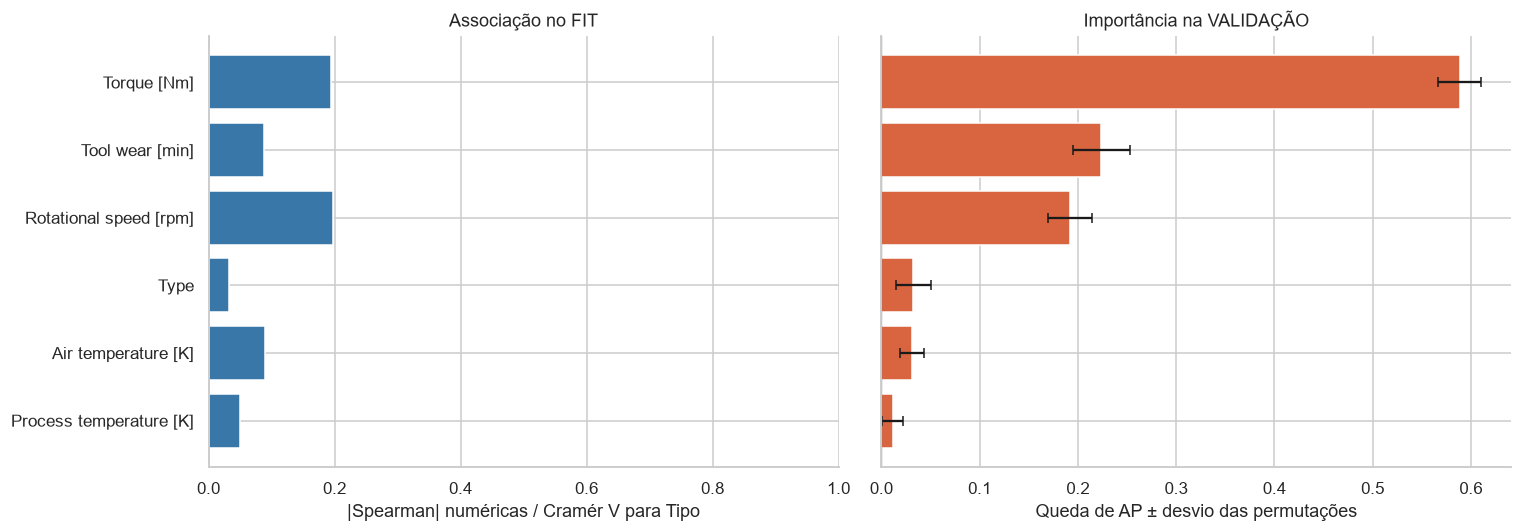

In [8]:
display(readable_table(report.table('feature_association_importance')))
report.feature_figure()

## 9. Diagnóstico por tamanho do prefixo

Parâmetros congelados da busca, prefixos ordenados e a mesma validação. Prefixos
de tamanhos distintos abrangem regimes diferentes: **não é uma learning curve i.i.d.
controlada**. É diagnóstico descritivo; não escolhe novamente os parâmetros.

,Observações de treino,Origem,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),AUPRC trapezoidal (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,1.600,Treino (prefixo),1.600,45,"2,81%","0,5000",1.555,0,0,45,"100,00%","100,00%","100,00%","100,00%","100,00%","0,00%","0,00%","2,81%","100,00%","100,00%","1,0000","1,0000",1,"0,0021","0,0127",1,1
1,1.600,Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.561,4,21,14,"52,83%","40,00%","77,78%","99,74%","98,67%","0,26%","60,00%","1,12%","98,44%","69,87%","0,6198","0,6162","0,9436","0,0171","0,0789","0,5512","0,5212"
2,3.200,Treino (prefixo),3.200,77,"2,41%","0,5000",3.123,0,8,69,"94,52%","89,61%","100,00%","100,00%","99,74%","0,00%","10,39%","2,16%","99,75%","94,81%",1,1,1,"0,0029","0,0144","0,9454","0,9439"
3,3.200,Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.562,3,19,16,"59,26%","45,71%","84,21%","99,81%","98,80%","0,19%","54,29%","1,19%","98,62%","72,76%","0,6809","0,6777","0,9363","0,0146","0,0709","0,6147","0,5862"
4,4.800,Treino (prefixo),4.800,221,"4,60%","0,5000",4.579,0,21,200,"95,01%","90,50%","100,00%","100,00%","99,54%","0,00%","9,50%","4,17%","99,56%","95,25%","0,9974","0,9974","0,9999","0,0051","0,0254","0,9491","0,9478"
5,4.800,Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.561,4,21,14,"52,83%","40,00%","77,78%","99,74%","98,67%","0,26%","60,00%","1,12%","98,44%","69,87%","0,6728","0,6703","0,9310","0,0143","0,0712","0,5512","0,5212"
6,6.400,Treino (prefixo),6.400,265,"4,14%","0,5000",6.135,0,37,228,"92,49%","86,04%","100,00%","100,00%","99,40%","0,00%","13,96%","3,56%","99,42%","93,02%","0,9897","0,9896","0,9994","0,0069","0,0308","0,9248","0,9220"
7,6.400,Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.562,3,20,15,"56,60%","42,86%","83,33%","99,81%","98,74%","0,19%","57,14%","1,12%","98,56%","71,33%","0,7205","0,7180","0,9546","0,0111","0,0487","0,5917","0,5595"


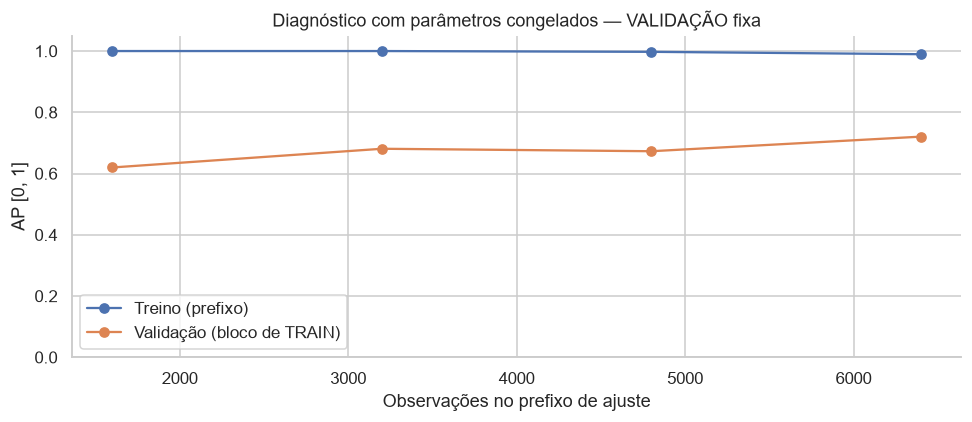

In [9]:
display(readable_table(report.table('learning_diagnostic')))
report.learning_figure()

## 10. Erros por segmento e ordem dos registros

Contagens, taxas reais, TP/FP/FN/TN e métricas por Type e faixas de sensores.
Limites das faixas aprendidos apenas em FIT; extremos cobrem valores futuros.
NaN indica denominador inexistente. Não somar suportes de features diferentes:
as mesmas observações aparecem em cada análise. UDI não representa tempo decorrido.

,Variável de agrupamento,Faixa / categoria,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),AUPRC trapezoidal (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,Tipo,H,147,1,"0,68%","0,5000",145,1,1,0,"0,00%","0,00%","0,00%","99,32%","99,32%","0,68%","100,00%","0,68%","98,64%","49,66%","0,5000","0,2500","0,9932","0,0070","0,0302","-0,0068","-0,0068"
1,Tipo,L,968,24,"2,48%","0,5000",942,2,12,12,"63,16%","50,00%","85,71%","99,79%","98,74%","0,21%","50,00%","1,45%","98,55%","74,89%","0,7398","0,7372","0,9398","0,0121","0,0542","0,6485","0,6247"
2,Tipo,M,485,10,"2,06%","0,5000",475,0,7,3,"46,15%","30,00%","100,00%","100,00%","98,55%","0,00%","70,00%","0,62%","98,56%","65,00%","0,8014","0,7933","0,9878","0,0106","0,0434","0,5437","0,4564"


,Variável de agrupamento,Faixa / categoria,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),AUPRC trapezoidal (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,Temperatura do ar [K],"(298.1, 299.6]",33,0,"0,00%","0,5000",33,0,0,0,"0,00%",Não definido,Não definido,"100,00%","100,00%","0,00%",Não definido,"0,00%","100,00%",Não definido,Não definido,Não definido,Não definido,"0,0010","0,0158",Não definido,Não definido
1,Temperatura do ar [K],"(299.6, 301.3]",1.359,30,"2,21%","0,5000",1.327,2,15,15,"63,83%","50,00%","88,24%","99,85%","98,88%","0,15%","50,00%","1,25%","98,75%","74,92%","0,7459","0,7436","0,9499","0,0106","0,0480","0,6590","0,6324"
2,Temperatura do ar [K],"(301.3, 302.4]",208,5,"2,40%","0,5000",202,1,5,0,"0,00%","0,00%","0,00%","99,51%","97,58%","0,49%","100,00%","0,48%","97,12%","49,75%","0,5176","0,4299","0,9783","0,0165","0,0584","-0,0109","-0,0081"
3,Temperatura do processo [K],"(309.4, 310.5]",521,9,"1,73%","0,5000",510,2,3,6,"70,59%","66,67%","75,00%","99,61%","99,42%","0,39%","33,33%","1,54%","99,04%","83,14%","0,7376","0,7348","0,8717","0,0092","0,0494","0,7023","0,7010"
4,Temperatura do processo [K],"(310.5, 311.3]",544,12,"2,21%","0,5000",531,1,7,5,"55,56%","41,67%","83,33%","99,81%","98,70%","0,19%","58,33%","1,10%","98,53%","70,74%","0,7739","0,7669","0,9904","0,0107","0,0423","0,5833","0,5489"
5,Temperatura do processo [K],"(311.3, inf]",535,14,"2,62%","0,5000",521,0,10,4,"44,44%","28,57%","100,00%","100,00%","98,12%","0,00%","71,43%","0,75%","98,13%","64,29%","0,7642","0,7582","0,9785","0,0135","0,0545","0,5295","0,4379"
6,Velocidade de rotação [rpm],"(-inf, 1406.0]",334,21,"6,29%","0,5000",311,2,11,10,"60,61%","47,62%","83,33%","99,36%","96,58%","0,64%","52,38%","3,59%","96,11%","73,49%","0,8103","0,8060","0,9840","0,0296","0,1236","0,6127","0,5872"
7,Velocidade de rotação [rpm],"(1406.0, 1469.0]",293,4,"1,37%","0,5000",289,0,3,1,"40,00%","25,00%","100,00%","100,00%","98,97%","0,00%","75,00%","0,34%","98,98%","62,50%","0,7292","0,6890","0,9948","0,0076","0,0311","0,4974","0,3967"
8,Velocidade de rotação [rpm],"(1469.0, 1542.0]",364,1,"0,27%","0,5000",363,0,1,0,"0,00%","0,00%",Não definido,"100,00%","99,73%","0,00%","100,00%","0,00%","99,73%","50,00%","0,1667","0,0833","0,9862","0,0026","0,0135",0,0
9,Velocidade de rotação [rpm],"(1542.0, 1643.0]",281,0,"0,00%","0,5000",281,0,0,0,"0,00%",Não definido,Não definido,"100,00%","100,00%","0,00%",Não definido,"0,00%","100,00%",Não definido,Não definido,Não definido,Não definido,"0,0001","0,0047",Não definido,Não definido


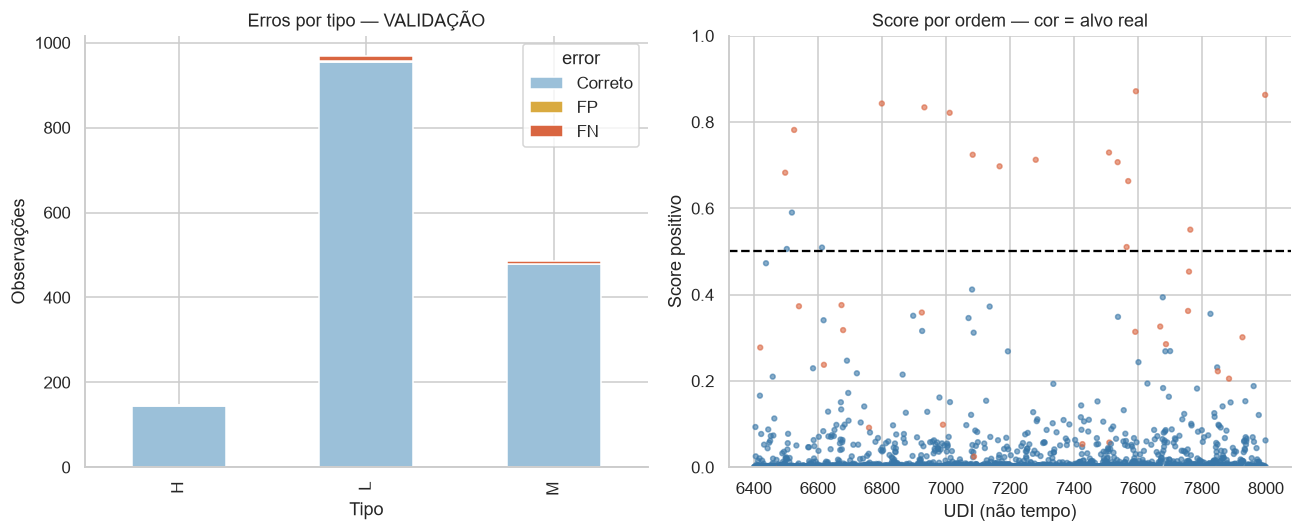

In [10]:
display(readable_table(report.table('segment_type')))
display(readable_table(report.table('segment_numeric')))
report.error_figure()

## 11. Artefato, reprodutibilidade e limites

O pipeline local corresponde ao refit em FIT (6.400), não a um modelo reajustado
nas 8.000 observações ou selecionado como vencedor do projeto. Não existe avaliação TEST.
O binário é local e ignorado no Git; carregar somente artefatos de origem confiável.

In [11]:
print('Pipeline:', manifest['model_path'])
print('SHA256:', manifest['model_sha256'])
print('Equivalência após serialização:', manifest['serialization_verified'])
print('Política de limiar:', manifest['threshold_policy'])
print('Figuras:', report.figures.relative_to(ROOT))
print('Tabelas:', report.tables.relative_to(ROOT))
display(manifest['limitations'])
display(translated_markdown('**Próxima decisão:** comparar os dois candidatos sob este mesmo protocolo, '
    'considerando AP, falhas perdidas, falsos alarmes, estabilidade e custo. '
    'Não ajustar features ou threshold com TEST. Nenhum vencedor de produção foi declarado.'))

Pipeline: models/train_random_forest_20261031T234425Z_5a1caa57/pipeline.joblib
SHA256: 9013b7f40e1780244851c15a2dee4274613703afdf498993944399c76065aa5f
Equivalência após serialização: True
Política de limiar: fixed reference; not tuned
Figuras: reports\figures\train_random_forest_20261031T234425Z_5a1caa57
Tabelas: reports\metrics\train_random_forest_20261031T234425Z_5a1caa57


['UDI is record order, not verified time',
 'no gap or physical machine ID',
 'CV winner scores are selection-optimistic',
 'validation belongs to EDA-explored TRAIN',
 'probability calibration not demonstrated',
 'no final TEST evaluation']

**Próxima decisão:** comparar os dois candidatos sob este mesmo protocolo, considerando AP, falhas perdidas, falsos alarmes, estabilidade e custo. Não ajustar features ou limiar com TEST. Nenhum vencedor de produção foi declarado.

## 12. Comparação com a execução anterior

Mesmos registros e folds. AUPRC trapezoidal e AP são calculadas com predict_proba[:, 1]; a execução anterior já usava predict_proba. Comparação na validação de desenvolvimento reutilizada; não demonstra generalização independente. O efeito conjunto de sampler, pesos e critério de busca não pode ser atribuído somente ao SMOTENC. TEST permanece reservado.

,Versão,Limiar de alerta,AUPRC trapezoidal (score),AP (score),F1 (%),Recall (%),Precision (%),FP: falsos alertas,FN: falhas não detectadas
0,Anterior,"0,5000","0,7180","0,7205","56,60%","42,86%","83,33%",3,20
1,Atual,"0,5000","0,7180","0,7205","56,60%","42,86%","83,33%",3,20


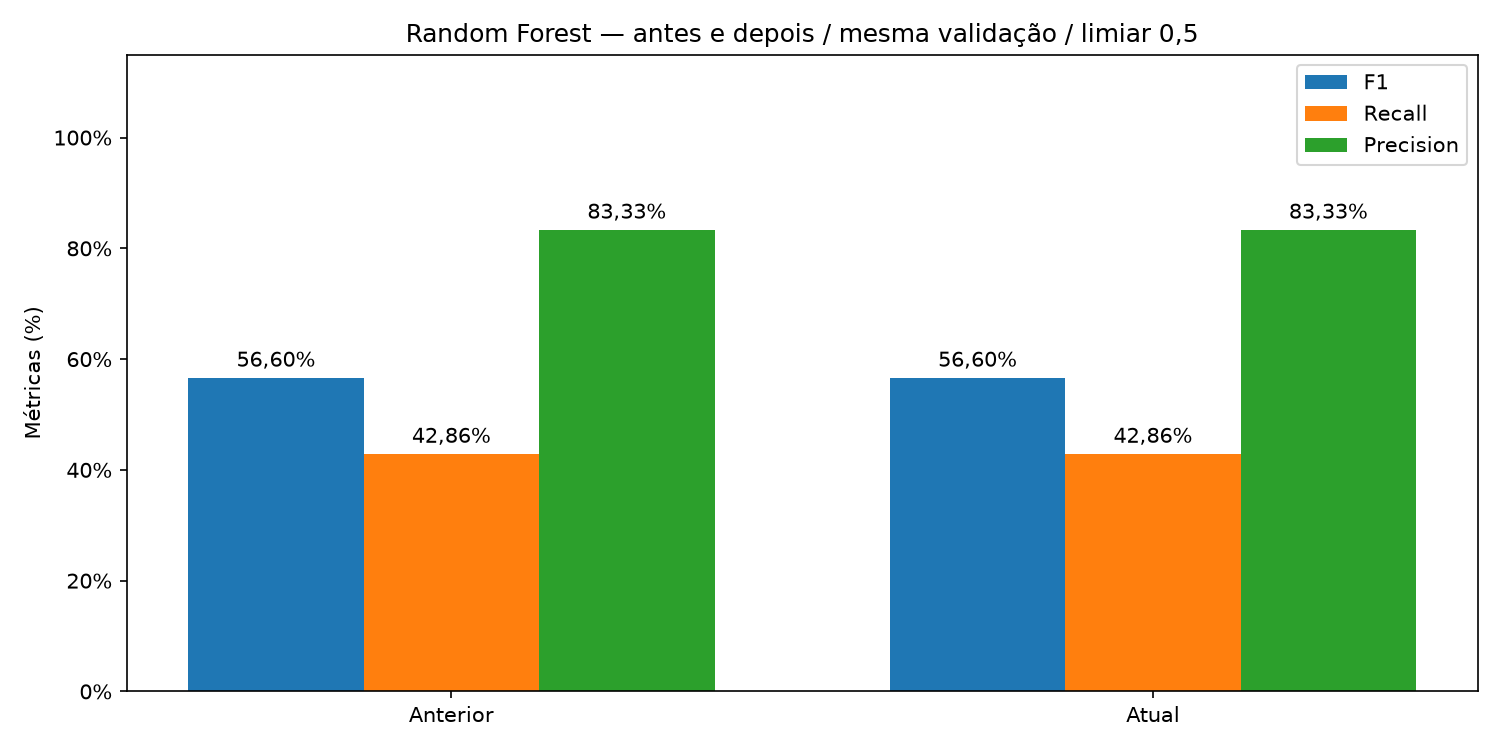

AUPRC: 0,7180 → 0,7180; AP: 0,7205 → 0,7205; F1: 56,60% → 56,60%. Não houve ajuste de limiar nesta comparação.

In [12]:
comparison = report.table('previous_comparison')
display(readable_table(comparison[['version', 'threshold', 'auprc', 'ap', 'f1', 'recall', 'precision', 'fp', 'fn']]))
from IPython.display import Image
display(Image(filename=str(report.figures / 'previous_comparison.png')))
before, after = comparison.iloc[0], comparison.iloc[1]
display(translated_markdown(f'AUPRC: {before.auprc:.4f} → {after.auprc:.4f}; ' f'AP: {before.ap:.4f} → {after.ap:.4f}; ' f'F1: {before.f1:.2%} → {after.f1:.2%}. ' 'Não houve ajuste de limiar nesta comparação.'))